In [4]:

import pandas as pd
import random
from datetime import date, timedelta
from pathlib import Path

# Keep the generated data consistent between runs
random.seed(42)

# Create a random date between two dates
def generate_date(start_date, end_date):
    days = (end_date - start_date).days
    return start_date + timedelta(days=random.randint(0, days))


# Sample names for our fictional customers
first_names = [
    "Aarav", "Priya", "Rahul", "Sneha", "Arjun",
    "Ananya", "Rohan", "Kavya", "Vikram", "Meera",
    "Aditya", "Divya", "Karan", "Neha", "Ishaan",
    "Pooja", "Amit", "Riya", "Nikhil", "Aisha"
]

last_names = [
    "Sharma", "Rao", "Shetty", "Patel", "Reddy",
    "Kumar", "Nair", "Iyer", "Mehta", "Verma",
    "Joshi", "Gupta", "Das", "Menon", "Singh"
]

locations = [
    ("Bengaluru", "Karnataka"),
    ("Mumbai", "Maharashtra"),
    ("Hyderabad", "Telangana"),
    ("Chennai", "Tamil Nadu"),
    ("Pune", "Maharashtra"),
    ("Kochi", "Kerala"),
    ("Delhi", "Delhi"),
    ("Jaipur", "Rajasthan"),
    ("Ahmedabad", "Gujarat"),
    ("Kolkata", "West Bengal")
]

plan_prices = {
    "Basic": 499,
    "Standard": 899,
    "Premium": 1499,
    "Family": 1999
}

payment_statuses = ["Paid", "Pending", "Failed"]


# Generate 2,000 fictional customer records
records = []

today = date.today()
signup_start = date(2022, 1, 1)
signup_end = today - timedelta(days=30)

for customer_id in range(100001, 102001):

    first = random.choice(first_names)
    last = random.choice(last_names)
    plan = random.choice(list(plan_prices.keys()))
    city, state = random.choice(locations)

    signup_date = generate_date(signup_start, signup_end)
    birth_date = generate_date(
        date(1960, 1, 1),
        date(2003, 12, 31)
    )

    last_payment = generate_date(signup_date, today)

    record = {
        "customer_id": customer_id,
        "first_name": first,
        "last_name": last,
        "email": f"{first.lower()}.{last.lower()}.{customer_id}@example.com",
        "phone_number": f"+91-{random.randint(6000000000, 9999999999)}",
        "date_of_birth": birth_date.isoformat(),
        "signup_date": signup_date.isoformat(),
        "city": city,
        "state": state,
        "subscription_plan": plan,
        "monthly_fee": plan_prices[plan],
        "payment_status": random.choice(payment_statuses),
        "last_payment_date": last_payment.isoformat()
    }

    records.append(record)


# Convert the records into a Pandas table
df = pd.DataFrame(records)


# Now deliberately introduce data-quality problems
all_rows = df.index.tolist()

# 1. Missing email addresses
missing_email_rows = random.sample(all_rows, 60)
df.loc[missing_email_rows, "email"] = None

# 2. Incorrect email formats
available_rows = [
    row for row in all_rows if row not in missing_email_rows
]
bad_email_rows = random.sample(available_rows, 20)

for row in bad_email_rows:
    df.loc[row, "email"] = random.choice([
        "invalid-email",
        "customer.example.com",
        "name@"
    ])

# 3. Missing phone numbers
missing_phone_rows = random.sample(all_rows, 30)
df.loc[missing_phone_rows, "phone_number"] = None

# 4. Invalid signup dates
bad_signup_rows = random.sample(all_rows, 20)
df.loc[bad_signup_rows, "signup_date"] = "not-a-date"

# 5. Invalid last payment dates
bad_payment_date_rows = random.sample(all_rows, 15)
df.loc[bad_payment_date_rows, "last_payment_date"] = "2025-02-30"

# 6. Inconsistent subscription plan formatting
plan_format_rows = random.sample(all_rows, 80)
inconsistent_plans = [
    " basic ", "STANDARD", "premium ", " FAMILY ", "sTaNdArD"
]

for row in plan_format_rows:
    df.loc[row, "subscription_plan"] = random.choice(
        inconsistent_plans
    )

# 7. Unexpected subscription plans
available_plan_rows = [
    row for row in all_rows if row not in plan_format_rows
]
unexpected_plan_rows = random.sample(available_plan_rows, 15)

for row in unexpected_plan_rows:
    df.loc[row, "subscription_plan"] = "Gold"

# 8. Inconsistent payment status formatting
messy_status_rows = random.sample(all_rows, 100)

for row in messy_status_rows:
    df.loc[row, "payment_status"] = random.choice([
        "paid", " PENDING ", "FAILED", "paid "
    ])

# 9. Missing payment statuses
missing_status_rows = random.sample(all_rows, 25)
df.loc[missing_status_rows, "payment_status"] = None

# 10. Invalid monthly fees
negative_fee_rows = random.sample(all_rows, 10)
df.loc[negative_fee_rows, "monthly_fee"] = -100

# 11. Add 30 exact duplicate records
duplicate_records = df.sample(n=30, random_state=42)
df = pd.concat([df, duplicate_records], ignore_index=True)


# Save the dataset in our project's data folder
data_folder = Path("../data")
data_folder.mkdir(parents=True, exist_ok=True)

output_file = data_folder / "synthetic_customers.csv"
df.to_csv(output_file, index=False)


# Show the result
print("Synthetic dataset created successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Saved to:", output_file.resolve())

display(df.head(10))


Synthetic dataset created successfully!
Rows: 2030
Columns: 13
Saved to: C:\Users\shree\OneDrive\Documents\LLM_Data_Quality_Assistant\data\synthetic_customers.csv


,customer_id,first_name,last_name,email,phone_number,date_of_birth,signup_date,city,state,subscription_plan,monthly_fee,payment_status,last_payment_date
0,100001,Sneha,Sharma,sneha.sharma.100001@example.com,+91-8906402157,1966-04-05,2023-04-03,Chennai,Tamil Nadu,Premium,1499,Failed,2023-10-29
1,100002,Riya,Rao,riya.rao.100002@example.com,+91-6999270936,1964-03-15,2022-03-03,Bengaluru,Karnataka,Family,1999,Failed,2023-05-24
2,100003,Aisha,Sharma,aisha.sharma.100003@example.com,+91-8530876844,1969-11-20,2024-05-09,Ahmedabad,Gujarat,Standard,899,Pending,2025-08-11
3,100004,Aarav,Das,aarav.das.100004@example.com,+91-6924765563,1972-06-18,2023-11-28,Delhi,Delhi,Standard,899,Pending,2024-10-11
4,100005,Sneha,Rao,sneha.rao.100005@example.com,+91-8592983555,1998-01-06,2024-01-06,Mumbai,Maharashtra,Family,1999,Pending,2024-12-23
5,100006,Priya,Gupta,priya.gupta.100006@example.com,+91-6338444264,2003-08-26,2022-09-13,Ahmedabad,Gujarat,Family,1999,Failed,2024-10-27
6,100007,Meera,Menon,meera.menon.100007@example.com,+91-6196814233,1991-08-09,2023-01-29,Kolkata,West Bengal,Premium,1499,Failed,2023-06-20
7,100008,Kavya,Das,kavya.das.100008@example.com,+91-7632629719,1998-11-13,not-a-date,Mumbai,Maharashtra,Premium,1499,Pending,2023-11-14
8,100009,Ishaan,Joshi,ishaan.joshi.100009@example.com,+91-8878380452,1975-12-08,2024-01-29,Hyderabad,Telangana,Premium,1499,Pending,2024-08-30
9,100010,Rahul,Verma,rahul.verma.100010@example.com,+91-7985392498,1970-12-24,2026-02-02,Ahmedabad,Gujarat,Standard,899,Pending,2026-04-26


In [5]:

import pandas as pd
from pathlib import Path

# Load the synthetic customer dataset
df = pd.read_csv("../data/synthetic_customers.csv")

# Create an empty list to store data-quality issues
issues = []


# Function to add an issue to our report
def add_issue(row_index, issue_type, column,
              current_value, severity, recommended_action):

    customer = df.iloc[row_index]

    issues.append({
        "record_number": row_index + 2,
        "customer_id": customer["customer_id"],
        "issue_type": issue_type,
        "column": column,
        "current_value": str(current_value),
        "severity": severity,
        "recommended_action": recommended_action
    })


# 1. Find missing values
for column in df.columns:

    missing_rows = df.index[df[column].isna()]

    for row_index in missing_rows:
        add_issue(
            row_index,
            "Missing Value",
            column,
            "Missing",
            "Medium",
            "Review the record and fill in the missing value."
        )


# 2. Find duplicate records
duplicate_rows = df.index[df.duplicated(keep=False)]

for row_index in duplicate_rows:
    add_issue(
        row_index,
        "Duplicate Record",
        "Entire Record",
        "Duplicate row",
        "Medium",
        "Review duplicate records and remove only if appropriate."
    )


# 3. Find invalid dates
date_columns = [
    "date_of_birth",
    "signup_date",
    "last_payment_date"
]

for column in date_columns:

    converted_dates = pd.to_datetime(
        df[column], errors="coerce"
    )

    invalid_rows = df.index[
        df[column].notna() & converted_dates.isna()
    ]

    for row_index in invalid_rows:
        add_issue(
            row_index,
            "Invalid Date",
            column,
            df.loc[row_index, column],
            "High",
            "Verify the date and enter it in a valid format."
        )


# 4. Find invalid email addresses
email_pattern = r"^[^@\s]+@[^@\s]+\.[^@\s]+$"

invalid_emails = df.index[
    df["email"].notna()
    & ~df["email"].astype(str).str.match(email_pattern)
]

for row_index in invalid_emails:
    add_issue(
        row_index,
        "Invalid Email",
        "email",
        df.loc[row_index, "email"],
        "Medium",
        "Check the email address format."
    )


# 5. Find inconsistent category formatting
category_columns = ["subscription_plan", "payment_status"]

for column in category_columns:

    cleaned_values = (
        df[column].astype("string").str.strip().str.title()
    )

    inconsistent_rows = df.index[
        df[column].notna()
        & df[column].ne(cleaned_values)
    ]

    for row_index in inconsistent_rows:
        add_issue(
            row_index,
            "Inconsistent Formatting",
            column,
            df.loc[row_index, column],
            "Low",
            "Standardize spaces and capitalization."
        )


# 6. Find unexpected subscription plans
valid_plans = ["Basic", "Standard", "Premium", "Family"]

standard_plans = (
    df["subscription_plan"]
    .astype("string").str.strip().str.title()
)

unexpected_rows = df.index[
    df["subscription_plan"].notna()
    & ~standard_plans.isin(valid_plans)
]

for row_index in unexpected_rows:
    add_issue(
        row_index,
        "Unexpected Category",
        "subscription_plan",
        df.loc[row_index, "subscription_plan"],
        "Medium",
        "Check whether the plan is approved."
    )


# 7. Find negative monthly fees
negative_fee_rows = df.index[df["monthly_fee"] < 0]

for row_index in negative_fee_rows:
    add_issue(
        row_index,
        "Invalid Value",
        "monthly_fee",
        df.loc[row_index, "monthly_fee"],
        "High",
        "Verify the fee against the approved pricing."
    )


# Convert all findings into a report
report = pd.DataFrame(issues)

# Save the report in the reports folder
reports_folder = Path("../reports")
reports_folder.mkdir(parents=True, exist_ok=True)

report_path = reports_folder / "data_quality_report.csv"
report.to_csv(report_path, index=False)


# Display the results
print("Data-quality check completed!")
print("Total customer records:", len(df))
print("Total issues found:", len(report))
print("\nIssues by category:")
print(report["issue_type"].value_counts())

print("\nSample findings:")
display(report.head(15))

print("\nReport saved to:", report_path.resolve())


Data-quality check completed!
Total customer records: 2030
Total issues found: 440

Issues by category:
issue_type
Inconsistent Formatting    183
Missing Value              116
Duplicate Record            60
Invalid Date                35
Invalid Email               20
Unexpected Category         15
Invalid Value               11
Name: count, dtype: int64

Sample findings:


,record_number,customer_id,issue_type,column,current_value,severity,recommended_action
0,75,100074,Missing Value,email,Missing,Medium,Review the record and fill in the missing value.
1,79,100078,Missing Value,email,Missing,Medium,Review the record and fill in the missing value.
2,138,100137,Missing Value,email,Missing,Medium,Review the record and fill in the missing value.
3,146,100145,Missing Value,email,Missing,Medium,Review the record and fill in the missing value.
4,173,100172,Missing Value,email,Missing,Medium,Review the record and fill in the missing value.
5,179,100178,Missing Value,email,Missing,Medium,Review the record and fill in the missing value.
6,224,100223,Missing Value,email,Missing,Medium,Review the record and fill in the missing value.
7,225,100224,Missing Value,email,Missing,Medium,Review the record and fill in the missing value.
8,230,100229,Missing Value,email,Missing,Medium,Review the record and fill in the missing value.
9,236,100235,Missing Value,email,Missing,Medium,Review the record and fill in the missing value.



Report saved to: C:\Users\shree\OneDrive\Documents\LLM_Data_Quality_Assistant\reports\data_quality_report.csv


ISSUES BY TYPE


,issue_type,issue_count,percentage
1,Inconsistent Formatting,183,41.59
5,Missing Value,116,26.36
0,Duplicate Record,60,13.64
2,Invalid Date,35,7.95
3,Invalid Email,20,4.55
6,Unexpected Category,15,3.41
4,Invalid Value,11,2.50


ISSUES BY SEVERITY


,severity,issue_count
0,High,46
1,Medium,211
2,Low,183


ISSUES BY COLUMN


,column,issue_count
4,payment_status,127
7,subscription_plan,97
1,email,80
0,Entire Record,60
5,phone_number,30
6,signup_date,20
2,last_payment_date,15
3,monthly_fee,11


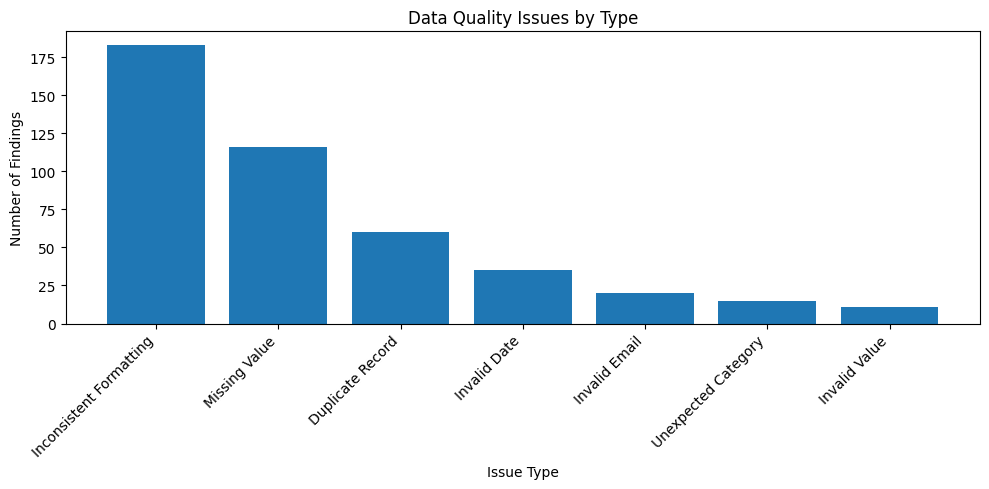


Summary reports and chart saved successfully!


In [6]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load the report created in the previous step
report = pd.read_csv("../reports/data_quality_report.csv")

# Create the reports folder if it doesn't exist
reports_folder = Path("../reports")
reports_folder.mkdir(parents=True, exist_ok=True)


# 1. Count issues by type
issue_summary = (
    report.groupby("issue_type")
    .size()
    .reset_index(name="issue_count")
    .sort_values("issue_count", ascending=False)
)

# Calculate each issue type's share of all findings
total_issues = len(report)

if total_issues > 0:
    issue_summary["percentage"] = (
        issue_summary["issue_count"] / total_issues * 100
    ).round(2)

# Save the issue summary
issue_summary.to_csv(
    reports_folder / "issue_summary.csv",
    index=False
)


# 2. Count issues by severity
severity_summary = (
    report["severity"]
    .value_counts()
    .reindex(["High", "Medium", "Low"], fill_value=0)
    .rename_axis("severity")
    .reset_index(name="issue_count")
)

severity_summary.to_csv(
    reports_folder / "severity_summary.csv",
    index=False
)


# 3. Count issues by column
column_summary = (
    report.groupby("column")
    .size()
    .reset_index(name="issue_count")
    .sort_values("issue_count", ascending=False)
)

column_summary.to_csv(
    reports_folder / "column_summary.csv",
    index=False
)


# 4. Display the summaries
print("ISSUES BY TYPE")
display(issue_summary)

print("ISSUES BY SEVERITY")
display(severity_summary)

print("ISSUES BY COLUMN")
display(column_summary)


# 5. Create a chart of issue types
plt.figure(figsize=(10, 5))

plt.bar(
    issue_summary["issue_type"],
    issue_summary["issue_count"]
)

plt.title("Data Quality Issues by Type")
plt.xlabel("Issue Type")
plt.ylabel("Number of Findings")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

# Save the chart
plt.savefig(
    reports_folder / "data_quality_issues_chart.png",
    dpi=150
)

plt.show()

print("\nSummary reports and chart saved successfully!")


In [7]:

import pandas as pd
from pathlib import Path

# Open the reports folder
reports_folder = Path("../reports")

# Load the summaries we created earlier
issue_summary = pd.read_csv(
    reports_folder / "issue_summary.csv"
)

severity_summary = pd.read_csv(
    reports_folder / "severity_summary.csv"
)

column_summary = pd.read_csv(
    reports_folder / "column_summary.csv"
)

# Prepare instructions and results for the AI model
prompt = f"""
You are a data quality assistant.

Analyze the following data quality findings.

Explain the results in simple English.

Include:
1. A short overall summary.
2. The most common data quality problems.
3. Why these problems matter.
4. Which problems should be investigated first.
5. Practical recommendations for the data team.

Do not invent facts or claim that data has been corrected.

ISSUES BY TYPE:
{issue_summary.to_string(index=False)}

ISSUES BY SEVERITY:
{severity_summary.to_string(index=False)}

ISSUES BY COLUMN:
{column_summary.to_string(index=False)}
"""

# Save the prepared prompt for the AI stage
prompt_path = reports_folder / "llm_analysis_prompt.txt"

with open(prompt_path, "w", encoding="utf-8") as file:
    file.write(prompt)

print("AI analysis prompt created successfully!")
print("\nPreview of the prompt:")
print(prompt[:1500])

print("\nSaved to:", prompt_path.resolve())


AI analysis prompt created successfully!

Preview of the prompt:

You are a data quality assistant.

Analyze the following data quality findings.

Explain the results in simple English.

Include:
1. A short overall summary.
2. The most common data quality problems.
3. Why these problems matter.
4. Which problems should be investigated first.
5. Practical recommendations for the data team.

Do not invent facts or claim that data has been corrected.

ISSUES BY TYPE:
             issue_type  issue_count  percentage
Inconsistent Formatting          183       41.59
          Missing Value          116       26.36
       Duplicate Record           60       13.64
           Invalid Date           35        7.95
          Invalid Email           20        4.55
    Unexpected Category           15        3.41
          Invalid Value           11        2.50

ISSUES BY SEVERITY:
severity  issue_count
    High           46
  Medium          211
     Low          183

ISSUES BY COLUMN:
           

In [1]:

import json
import urllib.request
import urllib.error
from pathlib import Path

# Load the AI prompt we created earlier
prompt_path = Path("../reports/llm_analysis_prompt.txt")
prompt = prompt_path.read_text(encoding="utf-8")

# Prepare the request for Ollama
request_data = {
    "model": "llama3.2:1b",
    "prompt": prompt,
    "stream": False
}

data = json.dumps(request_data).encode("utf-8")

request = urllib.request.Request(
    "http://localhost:11434/api/generate",
    data=data,
    headers={"Content-Type": "application/json"},
    method="POST"
)

try:
    # Send the prompt to the local AI model
    with urllib.request.urlopen(request, timeout=180) as response:
        result = json.loads(response.read().decode("utf-8"))

    # Get the AI's explanation
    ai_report = result["response"]

    # Save the explanation in the reports folder
    output_path = Path("../reports/llm_analysis_report.txt")
    output_path.write_text(ai_report, encoding="utf-8")

    print("AI analysis completed successfully!")
    print("\nAI Analysis:")
    print(ai_report)
    print("\nReport saved to:", output_path.resolve())

except urllib.error.URLError as error:
    print("Could not connect to Ollama.")
    print("Check that Ollama is running on your computer.")
    print("Details:", error)

except TimeoutError:
    print("The AI took too long to respond.")
    print("Try running the cell again.")


AI analysis completed successfully!

AI Analysis:
**Overall Summary:**
The data quality findings indicate several issues that need attention to ensure the quality and reliability of the data. The most common problems are inconsistent formatting, missing values, and duplicate records. These issues can lead to data inconsistencies, errors, and even data loss.

**Most Common Data Quality Problems:**

1. **Inconsistent formatting**: This issue can cause data inconsistencies and errors, as different formats may be used to represent the same data.
2. **Missing values**: Missing values can lead to data inconsistencies, errors, and even data loss. They can also cause issues when analyzing data.
3. **Duplicate records**: Duplicate records can lead to data inconsistencies and errors, as the same data is being reported multiple times.

**Why these problems matter:**
These issues are important because they can affect the accuracy and reliability of the data, leading to errors and inconsistencies i

In [2]:

import pandas as pd
import json
import urllib.request
from pathlib import Path

# Load the detailed data-quality report
report = pd.read_csv("../reports/data_quality_report.csv")

# Count each issue type by severity
severity_by_type = pd.crosstab(
    report["issue_type"],
    report["severity"]
).reindex(columns=["High", "Medium", "Low"], fill_value=0)

# Prepare clearer instructions for the AI
prompt = f"""
You are a data quality analyst.

Analyze the following findings from a synthetic customer dataset.

Explain in simple English:
1. The overall data-quality situation.
2. The most frequent problems.
3. The high-severity problems that need attention first.
4. Why these issues may matter.
5. Practical next steps for a data team.

Important rules:
- Distinguish frequent issues from high-severity issues.
- Use the severity assigned by the Python checks.
- Do not invent numbers or claim that data was corrected.
- Issue counts represent findings, not necessarily unique customers.
- Do not repeat the complete input tables in your answer.
- Clearly explain that the dataset is synthetic.

ISSUES BY TYPE AND SEVERITY:
{severity_by_type.to_string()}

TOTAL FINDINGS: {len(report)}
"""

# Save the improved prompt
prompt_path = Path("../reports/llm_analysis_prompt.txt")
prompt_path.write_text(prompt, encoding="utf-8")

# Send the prompt to our local Ollama model
request_data = {
    "model": "llama3.2:1b",
    "prompt": prompt,
    "stream": False
}

request = urllib.request.Request(
    "http://localhost:11434/api/generate",
    data=json.dumps(request_data).encode("utf-8"),
    headers={"Content-Type": "application/json"},
    method="POST"
)

with urllib.request.urlopen(request, timeout=180) as response:
    result = json.loads(response.read().decode("utf-8"))

# Save the improved AI explanation
ai_report = result["response"]

output_path = Path("../reports/llm_analysis_report.txt")
output_path.write_text(ai_report, encoding="utf-8")

print("Improved AI analysis generated successfully!")
print(ai_report)
print("\nSaved to:", output_path.resolve())


Improved AI analysis generated successfully!
**Data Quality Analysis: Synthetic Customer Dataset**

**Overall Data-Quality Situation:**
The data quality situation in this synthetic customer dataset is generally good, but there are some issues that need attention. There are 440 findings in total, indicating that there are some problems with the data that need to be addressed.

**Most Frequent Problems:**
The most frequent problems are:

1. Duplicate Record (0 occurrences)
2. Inconsistent Formatting (0 occurrences)
3. Missing Value (116 occurrences)

**High-Severity Problems:**
The most severe problems that need attention first are:

1. Invalid Date (35 occurrences)
2. Invalid Email (20 occurrences)
3. Invalid Value (11 occurrences)
4. Unexpected Category (15 occurrences)

These issues may matter because:

* Duplicate Records can lead to incorrect or unnecessary processing, costs, and customer frustration.
* Inconsistent Formatting can result in errors during processing, data cleaning, o

In [3]:
%pip install streamlit


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:

%%writefile ../app.py

import streamlit as st
import pandas as pd
from pathlib import Path

# Find our main project folder
BASE_DIR = Path(__file__).resolve().parent
DATA_DIR = BASE_DIR / "data"
REPORTS_DIR = BASE_DIR / "reports"

# Set up the dashboard
st.set_page_config(
    page_title="Data Quality Assistant",
    page_icon="📊",
    layout="wide"
)

st.title("LLM-Powered Data Quality Assistant")
st.caption(
    "A data-quality monitoring demo using Python, Pandas and a local LLM."
)


# Load a file safely
def load_csv(file_path):
    if file_path.exists():
        return pd.read_csv(file_path)
    return pd.DataFrame()


# Load the project files
customers = load_csv(DATA_DIR / "synthetic_customers.csv")
report = load_csv(REPORTS_DIR / "data_quality_report.csv")
issue_summary = load_csv(REPORTS_DIR / "issue_summary.csv")
severity_summary = load_csv(REPORTS_DIR / "severity_summary.csv")
column_summary = load_csv(REPORTS_DIR / "column_summary.csv")

ai_file = REPORTS_DIR / "llm_analysis_report.txt"


# Check whether the required data is available
if customers.empty:
    st.error("Customer dataset not found. Please check the data folder.")
    st.stop()

if report.empty:
    st.warning("No issue report found. Run the data-quality checker first.")
    st.stop()


# Show the main numbers
high_count = (
    int((report["severity"] == "High").sum())
    if "severity" in report.columns else 0
)

medium_count = (
    int((report["severity"] == "Medium").sum())
    if "severity" in report.columns else 0
)

low_count = (
    int((report["severity"] == "Low").sum())
    if "severity" in report.columns else 0
)

st.subheader("Quality Overview")

col1, col2, col3, col4 = st.columns(4)

col1.metric("Customer Records", f"{len(customers):,}")
col2.metric("Total Findings", f"{len(report):,}")
col3.metric("High Severity", f"{high_count:,}")
col4.metric("Columns with Issues", f"{report['column'].nunique():,}")


# Display charts
st.subheader("Data Quality Findings")

left, right = st.columns(2)

with left:
    st.write("**Issues by Type**")

    if not issue_summary.empty:
        chart_data = issue_summary.set_index("issue_type")["issue_count"]
        st.bar_chart(chart_data)
    else:
        st.info("Issue summary is not available.")

with right:
    st.write("**Issues by Severity**")

    severity_data = pd.DataFrame({
        "Severity": ["High", "Medium", "Low"],
        "Count": [high_count, medium_count, low_count]
    })

    st.bar_chart(severity_data.set_index("Severity"))


# Show which columns need attention
st.subheader("Issues by Column")

if not column_summary.empty:
    column_chart = column_summary.set_index("column")["issue_count"]
    st.bar_chart(column_chart)


# Allow users to filter the detailed report
st.subheader("Explore Individual Findings")

issue_options = ["All"] + sorted(
    report["issue_type"].dropna().unique().tolist()
)

severity_options = ["All"] + sorted(
    report["severity"].dropna().unique().tolist()
)

filter1, filter2 = st.columns(2)

with filter1:
    selected_issue = st.selectbox("Filter by issue type", issue_options)

with filter2:
    selected_severity = st.selectbox(
        "Filter by severity", severity_options
    )

filtered_report = report.copy()

if selected_issue != "All":
    filtered_report = filtered_report[
        filtered_report["issue_type"] == selected_issue
    ]

if selected_severity != "All":
    filtered_report = filtered_report[
        filtered_report["severity"] == selected_severity
    ]

st.write(f"Showing {len(filtered_report):,} findings")
st.dataframe(filtered_report, use_container_width=True)


# Download buttons
st.subheader("Download Reports")

download1, download2, download3 = st.columns(3)

with download1:
    st.download_button(
        label="Download Issue Report",
        data=report.to_csv(index=False).encode("utf-8"),
        file_name="data_quality_report.csv",
        mime="text/csv"
    )

with download2:
    st.download_button(
        label="Download Customer Dataset",
        data=customers.to_csv(index=False).encode("utf-8"),
        file_name="synthetic_customers.csv",
        mime="text/csv"
    )

with download3:
    if ai_file.exists():
        st.download_button(
            label="Download AI Analysis",
            data=ai_file.read_text(encoding="utf-8"),
            file_name="llm_analysis_report.txt",
            mime="text/plain"
        )
    else:
        st.info("Run the AI analysis to create its report.")


# Display the LLM-generated explanation
st.subheader("AI-Generated Analysis")

if ai_file.exists():
    ai_text = ai_file.read_text(encoding="utf-8")
    st.markdown(ai_text)
else:
    st.info("The AI analysis report has not been created yet.")

st.caption(
    "Note: This project uses synthetic data. Findings are alerts for "
    "review and do not mean the underlying records have been corrected."
)


Writing ../app.py


In [6]:

%%writefile ../quality_checker.py

import pandas as pd
from pathlib import Path

# Find the project folders
BASE_DIR = Path(__file__).resolve().parent
DATA_PATH = BASE_DIR / "data" / "synthetic_customers.csv"
REPORTS_DIR = BASE_DIR / "reports"


def run_quality_checks():

    # Load customer data
    df = pd.read_csv(DATA_PATH)
    issues = []

    # Store each problem found
    def add_issue(row, issue_type, column, value, severity, action):
        issues.append({
            "record_number": row + 2,
            "customer_id": df.iloc[row]["customer_id"],
            "issue_type": issue_type,
            "column": column,
            "current_value": str(value),
            "severity": severity,
            "recommended_action": action
        })

    # Check missing values
    for column in df.columns:
        for row in df.index[df[column].isna()]:
            add_issue(
                row, "Missing Value", column, "Missing",
                "Medium", "Review the missing value."
            )

    # Check duplicate records
    for row in df.index[df.duplicated(keep=False)]:
        add_issue(
            row, "Duplicate Record", "Entire Record",
            "Duplicate row", "Medium",
            "Review before removing the duplicate."
        )

    # Check invalid dates
    date_columns = [
        "date_of_birth", "signup_date", "last_payment_date"
    ]

    for column in date_columns:
        dates = pd.to_datetime(df[column], errors="coerce")
        bad_rows = df.index[df[column].notna() & dates.isna()]

        for row in bad_rows:
            add_issue(
                row, "Invalid Date", column, df.loc[row, column],
                "High", "Verify the date."
            )

    # Check email formats
    email_pattern = r"^[^@\s]+@[^@\s]+\.[^@\s]+$"

    bad_emails = df.index[
        df["email"].notna()
        & ~df["email"].astype(str).str.match(email_pattern)
    ]

    for row in bad_emails:
        add_issue(
            row, "Invalid Email", "email", df.loc[row, "email"],
            "Medium", "Verify the email address."
        )

    # Check category formatting
    for column in ["subscription_plan", "payment_status"]:
        original = df[column].astype("string")
        cleaned = original.str.strip().str.title()

        bad_rows = df.index[
            original.notna() & original.ne(cleaned)
        ]

        for row in bad_rows:
            add_issue(
                row, "Inconsistent Formatting", column,
                df.loc[row, column], "Low",
                "Review spaces and capitalization."
            )

    # Check approved subscription plans
    valid_plans = ["Basic", "Standard", "Premium", "Family"]

    plans = (
        df["subscription_plan"]
        .astype("string").str.strip().str.title()
    )

    bad_plans = df.index[
        df["subscription_plan"].notna()
        & ~plans.isin(valid_plans)
    ]

    for row in bad_plans:
        add_issue(
            row, "Unexpected Category", "subscription_plan",
            df.loc[row, "subscription_plan"], "Medium",
            "Check whether this plan is approved."
        )

    # Check negative fees
    fees = pd.to_numeric(df["monthly_fee"], errors="coerce")

    for row in df.index[fees < 0]:
        add_issue(
            row, "Invalid Value", "monthly_fee",
            df.loc[row, "monthly_fee"], "High",
            "Verify the fee against approved pricing."
        )

    # Convert findings into a table
    columns = [
        "record_number", "customer_id", "issue_type", "column",
        "current_value", "severity", "recommended_action"
    ]

    report = pd.DataFrame(issues, columns=columns)

    # Create the reports folder
    REPORTS_DIR.mkdir(parents=True, exist_ok=True)

    # Save detailed findings
    report.to_csv(
        REPORTS_DIR / "data_quality_report.csv", index=False
    )

    # Save summary by issue type
    issue_summary = (
        report["issue_type"].value_counts()
        .rename_axis("issue_type")
        .reset_index(name="issue_count")
    )

    if len(report) > 0:
        issue_summary["percentage"] = (
            issue_summary["issue_count"] / len(report) * 100
        ).round(2)

    issue_summary.to_csv(
        REPORTS_DIR / "issue_summary.csv", index=False
    )

    # Save summary by severity
    severity_summary = (
        report["severity"].value_counts()
        .reindex(["High", "Medium", "Low"], fill_value=0)
        .rename_axis("severity")
        .reset_index(name="issue_count")
    )

    severity_summary.to_csv(
        REPORTS_DIR / "severity_summary.csv", index=False
    )

    # Save summary by column
    column_summary = (
        report["column"].value_counts()
        .rename_axis("column")
        .reset_index(name="issue_count")
    )

    column_summary.to_csv(
        REPORTS_DIR / "column_summary.csv", index=False
    )

    # Prepare an updated prompt for the local AI model
    prompt = f"""
You are a data quality analyst.

Analyze findings from a synthetic customer dataset.
Explain the overall situation, common problems, their impact,
which problems to investigate first, and practical next steps.

Distinguish frequent problems from high-severity problems.
Use only the supplied information.
Do not claim the data has been corrected.
Counts represent findings, not necessarily unique customers.

Issues by type:
{issue_summary.to_string(index=False)}

Issues by severity:
{severity_summary.to_string(index=False)}

Issues by column:
{column_summary.to_string(index=False)}
"""

    (REPORTS_DIR / "llm_analysis_prompt.txt").write_text(
        prompt, encoding="utf-8"
    )

    return len(df), len(report)


# Run the checks when this file is executed
if __name__ == "__main__":
    records, findings = run_quality_checks()

    print("Data-quality checks completed!")
    print("Customer records checked:", records)
    print("Issues found:", findings)
    print("Reports saved in:", REPORTS_DIR)


Writing ../quality_checker.py


In [7]:
%run ../quality_checker.py

Data-quality checks completed!
Customer records checked: 2030
Issues found: 440
Reports saved in: C:\Users\shree\OneDrive\Documents\LLM_Data_Quality_Assistant\reports


In [8]:

%%writefile ../app.py

import json
import urllib.request
import urllib.error
from pathlib import Path

import pandas as pd
import streamlit as st

from quality_checker import run_quality_checks


# Find the project folders
BASE_DIR = Path(__file__).resolve().parent
DATA_DIR = BASE_DIR / "data"
REPORTS_DIR = BASE_DIR / "reports"


# Set up the dashboard
st.set_page_config(
    page_title="Data Quality Assistant",
    page_icon="📊",
    layout="wide"
)

st.title("LLM-Powered Data Quality Assistant")
st.caption(
    "Detect, review and explain data-quality issues using Python and AI."
)


# Create two action buttons
button1, button2 = st.columns(2)

with button1:
    if st.button("Run Data Quality Checks", type="primary"):
        try:
            records, findings = run_quality_checks()

            st.success(
                f"Checked {records:,} records and found "
                f"{findings:,} data-quality findings."
            )
        except Exception as error:
            st.error(f"Could not run the checks: {error}")

with button2:
    if st.button("Generate AI Analysis"):
        prompt_path = REPORTS_DIR / "llm_analysis_prompt.txt"

        try:
            prompt = prompt_path.read_text(encoding="utf-8")

            request_data = {
                "model": "llama3.2:1b",
                "prompt": prompt,
                "stream": False
            }

            request = urllib.request.Request(
                "http://localhost:11434/api/generate",
                data=json.dumps(request_data).encode("utf-8"),
                headers={"Content-Type": "application/json"},
                method="POST"
            )

            with urllib.request.urlopen(
                request, timeout=180
            ) as response:
                result = json.loads(
                    response.read().decode("utf-8")
                )

            ai_report = result["response"]

            output_path = (
                REPORTS_DIR / "llm_analysis_report.txt"
            )
            output_path.write_text(
                ai_report, encoding="utf-8"
            )

            st.success("AI analysis generated successfully!")

        except urllib.error.URLError:
            st.error(
                "Could not connect to Ollama. "
                "Check that Ollama is running."
            )
        except Exception as error:
            st.error(f"Could not generate the AI analysis: {error}")


# Load project files
def load_csv(file_path):
    if file_path.exists():
        return pd.read_csv(file_path)
    return pd.DataFrame()


customers = load_csv(DATA_DIR / "synthetic_customers.csv")
report = load_csv(REPORTS_DIR / "data_quality_report.csv")
issue_summary = load_csv(REPORTS_DIR / "issue_summary.csv")
severity_summary = load_csv(REPORTS_DIR / "severity_summary.csv")
column_summary = load_csv(REPORTS_DIR / "column_summary.csv")


# Check whether reports are available
if customers.empty:
    st.warning("Customer dataset not found.")
    st.stop()

if report.empty:
    st.info("Click Run Data Quality Checks to create the report.")
    st.stop()


# Display key metrics
st.subheader("Quality Overview")

high_count = int((report["severity"] == "High").sum())
medium_count = int((report["severity"] == "Medium").sum())
low_count = int((report["severity"] == "Low").sum())

col1, col2, col3, col4 = st.columns(4)

col1.metric("Customer Records", f"{len(customers):,}")
col2.metric("Total Findings", f"{len(report):,}")
col3.metric("High Severity", f"{high_count:,}")
col4.metric("Columns with Issues", f"{report['column'].nunique():,}")


# Display charts
st.subheader("Data Quality Findings")

left, right = st.columns(2)

with left:
    st.write("**Issues by Type**")

    if not issue_summary.empty:
        chart = issue_summary.set_index("issue_type")["issue_count"]
        st.bar_chart(chart)

with right:
    st.write("**Issues by Severity**")

    severity_chart = pd.DataFrame({
        "Severity": ["High", "Medium", "Low"],
        "Count": [high_count, medium_count, low_count]
    })

    st.bar_chart(severity_chart.set_index("Severity"))


# Show issues by column
st.subheader("Issues by Column")

if not column_summary.empty:
    chart = column_summary.set_index("column")["issue_count"]
    st.bar_chart(chart)


# Filter individual findings
st.subheader("Explore Findings")

filter1, filter2 = st.columns(2)

with filter1:
    issue_options = ["All"] + sorted(
        report["issue_type"].dropna().unique().tolist()
    )
    selected_issue = st.selectbox(
        "Issue Type", issue_options
    )

with filter2:
    severity_options = ["All"] + sorted(
        report["severity"].dropna().unique().tolist()
    )
    selected_severity = st.selectbox(
        "Severity", severity_options
    )

filtered_report = report.copy()

if selected_issue != "All":
    filtered_report = filtered_report[
        filtered_report["issue_type"] == selected_issue
    ]

if selected_severity != "All":
    filtered_report = filtered_report[
        filtered_report["severity"] == selected_severity
    ]

st.write(f"Showing {len(filtered_report):,} findings")
st.dataframe(filtered_report, use_container_width=True)


# Display the latest AI explanation
st.subheader("AI-Generated Analysis")

ai_path = REPORTS_DIR / "llm_analysis_report.txt"

if ai_path.exists():
    st.markdown(ai_path.read_text(encoding="utf-8"))
else:
    st.info("Click Generate AI Analysis to create an explanation.")


# Download the reports
st.subheader("Download Files")

st.download_button(
    "Download Issue Report",
    data=report.to_csv(index=False).encode("utf-8"),
    file_name="data_quality_report.csv",
    mime="text/csv"
)

st.download_button(
    "Download Customer Dataset",
    data=customers.to_csv(index=False).encode("utf-8"),
    file_name="synthetic_customers.csv",
    mime="text/csv"
)

if ai_path.exists():
    st.download_button(
        "Download AI Analysis",
        data=ai_path.read_text(encoding="utf-8"),
        file_name="llm_analysis_report.txt",
        mime="text/plain"
    )

st.caption(
    "This demonstration uses synthetic data. Findings are alerts "
    "for review; the original customer data is not automatically corrected."
)


Overwriting ../app.py


In [9]:

%%writefile ../test_quality_checker.py

from pathlib import Path
import sys
import pandas as pd

# Find the main project folder
BASE_DIR = Path(__file__).resolve().parent

# Allow Python to find quality_checker.py
sys.path.insert(0, str(BASE_DIR))

from quality_checker import run_quality_checks


# Run the data-quality checker
records_checked, findings_found = run_quality_checks()

# Load the dataset and generated report
customers = pd.read_csv(
    BASE_DIR / "data" / "synthetic_customers.csv"
)

report = pd.read_csv(
    BASE_DIR / "reports" / "data_quality_report.csv"
)


# Test 1: Check that the dataset has enough records
assert len(customers) >= 2000, "Dataset has too few records"

# Test 2: Check that the expected columns exist
assert customers.shape[1] == 13, "Unexpected number of columns"

# Test 3: Check that the report contains findings
assert not report.empty, "No data-quality findings were generated"

# Test 4: Check that all expected issue types were detected
expected_issues = {
    "Missing Value",
    "Duplicate Record",
    "Invalid Date",
    "Invalid Email",
    "Inconsistent Formatting",
    "Unexpected Category",
    "Invalid Value"
}

detected_issues = set(report["issue_type"])
missing_issues = expected_issues - detected_issues

assert not missing_issues, (
    f"These issue types were not detected: {missing_issues}"
)

# Test 5: Check that severity labels are valid
valid_severities = {"High", "Medium", "Low"}

assert set(report["severity"]).issubset(valid_severities), (
    "Unexpected severity label found"
)

# Test 6: Check that the reported count matches the report
assert findings_found == len(report), (
    "The reported finding count does not match the report"
)

print("All automated tests passed!")
print("Customer records checked:", records_checked)
print("Data-quality findings:", findings_found)
print("Issue types detected:", len(detected_issues))


Writing ../test_quality_checker.py


In [10]:
%run ../test_quality_checker.py

All automated tests passed!
Customer records checked: 2030
Data-quality findings: 440
Issue types detected: 7


In [12]:

import json
from datetime import datetime
from pathlib import Path
import pandas as pd

# Locate our project folders
data_path = Path("../data/synthetic_customers.csv")
reports_folder = Path("../reports")

# Load the dataset
df = pd.read_csv(data_path)

# Load the latest data-quality report
report_path = reports_folder / "data_quality_report.csv"
report = pd.read_csv(report_path)

# Collect details about each column
column_details = []

for column in df.columns:
    column_details.append({
        "column_name": column,
        "data_type": str(df[column].dtype),
        "missing_values": int(df[column].isna().sum())
    })

# Create the metadata
metadata = {
    "project_name": "LLM-Powered Data Quality Assistant",
    "generated_at": datetime.now().astimezone().isoformat(),
    "dataset": {
        "file_name": "synthetic_customers.csv",
        "source": "Synthetic data generated using Python",
        "rows": int(df.shape[0]),
        "columns": int(df.shape[1]),
        "column_details": column_details
    },
    "quality_check": {
        "checker": "quality_checker.py",
        "total_findings": int(len(report)),
        "original_dataset_modified": False
    }
}

# Save metadata as a JSON file
metadata_path = reports_folder / "metadata.json"

with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=4)

# Document how the data moves through the project
lineage = f"""
# Data Lineage

## Data Source
File: data/synthetic_customers.csv

Source: Synthetic customer data generated using Python.
No real customer records are used.

## Processing Flow
1. Python generates the synthetic customer dataset.
2. Pandas loads the dataset.
3. quality_checker.py checks for data-quality issues.
4. Findings are saved in data_quality_report.csv.
5. Summary reports are generated by issue type, severity and column.
6. An AI prompt is prepared from the findings.
7. Ollama generates a plain-English explanation.
8. Streamlit displays the findings and reports.

## Dataset Information
- Rows: {len(df)}
- Columns: {len(df.columns)}
- Data-quality findings: {len(report)}

## Important Notes
- The dataset is synthetic.
- Findings identify potential problems; they do not automatically
  correct the original records.
- AI recommendations should be reviewed before taking action.

## Generated At
{datetime.now().astimezone().isoformat()}
"""

# Save the lineage document
lineage_path = reports_folder / "data_lineage.md"
lineage_path.write_text(lineage, encoding="utf-8")

print("Metadata and data lineage created successfully!")
print("Dataset rows:", len(df))
print("Dataset columns:", len(df.columns))
print("Data-quality findings:", len(report))
print("Metadata saved to:", metadata_path.resolve())
print("Lineage saved to:", lineage_path.resolve())


Metadata and data lineage created successfully!
Dataset rows: 2030
Dataset columns: 13
Data-quality findings: 440
Metadata saved to: C:\Users\shree\OneDrive\Documents\LLM_Data_Quality_Assistant\reports\metadata.json
Lineage saved to: C:\Users\shree\OneDrive\Documents\LLM_Data_Quality_Assistant\reports\data_lineage.md


In [13]:

from pathlib import Path
import pandas as pd
import json

# Find the main project folder
project_folder = Path("..").resolve()
data_folder = project_folder / "data"
reports_folder = project_folder / "reports"

# Check the important project files
files_to_check = {
    "Synthetic dataset": data_folder / "synthetic_customers.csv",
    "Quality checker": project_folder / "quality_checker.py",
    "Streamlit dashboard": project_folder / "app.py",
    "Automated tests": project_folder / "test_quality_checker.py",
    "Detailed issue report": reports_folder / "data_quality_report.csv",
    "Issue summary": reports_folder / "issue_summary.csv",
    "Severity summary": reports_folder / "severity_summary.csv",
    "Column summary": reports_folder / "column_summary.csv",
    "AI prompt": reports_folder / "llm_analysis_prompt.txt",
    "AI analysis": reports_folder / "llm_analysis_report.txt",
    "Metadata": reports_folder / "metadata.json",
    "Data lineage": reports_folder / "data_lineage.md"
}

print("PROJECT FILE CHECK")
print("-" * 40)

for name, path in files_to_check.items():
    status = "FOUND" if path.exists() else "MISSING"
    print(f"{name}: {status}")

# Check the dataset
dataset_path = data_folder / "synthetic_customers.csv"
if dataset_path.exists():
    customers = pd.read_csv(dataset_path)
    print("\nDATASET CHECK")
    print("Rows:", len(customers))
    print("Columns:", len(customers.columns))

# Check the detailed report
report_path = reports_folder / "data_quality_report.csv"
if report_path.exists():
    report = pd.read_csv(report_path)

    print("\nQUALITY REPORT CHECK")
    print("Total findings:", len(report))
    print("Issue types detected:", report["issue_type"].nunique())
    print("\nFindings by type:")
    print(report["issue_type"].value_counts())

# Check the metadata file
metadata_path = reports_folder / "metadata.json"
if metadata_path.exists():
    with open(metadata_path, "r", encoding="utf-8") as file:
        metadata = json.load(file)

    print("\nMETADATA CHECK")
    print("Project:", metadata["project_name"])
    print("Recorded dataset rows:", metadata["dataset"]["rows"])

print("\nVerification completed.")


PROJECT FILE CHECK
----------------------------------------
Synthetic dataset: FOUND
Quality checker: FOUND
Streamlit dashboard: FOUND
Automated tests: FOUND
Detailed issue report: FOUND
Issue summary: FOUND
Severity summary: FOUND
Column summary: FOUND
AI prompt: FOUND
AI analysis: FOUND
Metadata: FOUND
Data lineage: FOUND

DATASET CHECK
Rows: 2030
Columns: 13

QUALITY REPORT CHECK
Total findings: 440
Issue types detected: 7

Findings by type:
issue_type
Inconsistent Formatting    183
Missing Value              116
Duplicate Record            60
Invalid Date                35
Invalid Email               20
Unexpected Category         15
Invalid Value               11
Name: count, dtype: int64

METADATA CHECK
Project: LLM-Powered Data Quality Assistant
Recorded dataset rows: 2030

Verification completed.


In [14]:
#Create README and requirements files

from pathlib import Path

# Find the main project folder
project_folder = Path("..").resolve()

# Write the project README
readme_content = """
# LLM-Powered Data Quality Assistant

## Project Overview

This project detects common data-quality problems in a synthetic
customer subscription dataset. It uses Python and Pandas to identify
potential issues, creates reports and charts, and uses a local
language model through Ollama to explain the findings in simple English.

A Streamlit dashboard allows users to explore findings, filter results,
and download reports.

## Features

- Generates a synthetic customer dataset with 2,030 records.
- Detects missing values and duplicate records.
- Identifies invalid dates and email formats.
- Detects inconsistent category formatting.
- Flags unexpected subscription plans and negative fees.
- Creates detailed issue reports and summary CSV files.
- Uses a local LLM to explain findings and recommend next steps.
- Provides a Streamlit dashboard with charts and filters.
- Includes automated tests, dataset metadata, and data lineage notes.

## Technology Stack

- Python
- Pandas
- Matplotlib
- Streamlit
- Ollama
- Llama 3.2 (1B)
- Jupyter Notebook

## Project Structure

```text
LLM_Data_Quality_Assistant/
├── app.py
├── quality_checker.py
├── test_quality_checker.py
├── metadata_and_lineage.py
├── requirements.txt
├── README.md
├── data/
│   └── synthetic_customers.csv
├── notebooks/
│   └── data_quality_assistant.ipynb
└── reports/
    ├── data_quality_report.csv
    ├── issue_summary.csv
    ├── severity_summary.csv
    ├── column_summary.csv
    ├── llm_analysis_prompt.txt
    ├── llm_analysis_report.txt
    ├── metadata.json
    └── data_lineage.md
```

## Setup

### 1. Install Python packages

From the main project folder, run:

```bash
python -m pip install -r requirements.txt
```

### 2. Install Ollama

Install Ollama from:

https://ollama.com/download/windows

Download the model using:

```bash
ollama run llama3.2:1b
```

Keep Ollama available while generating AI analysis.

### 3. Run the data-quality checks

From the main project folder, run:

```bash
python quality_checker.py
```

This reads the synthetic dataset and creates the detailed report
and summary CSV files.

### 4. Launch the dashboard

From the main project folder, run:

```bash
python -m streamlit run app.py
```

Open the local address shown in the terminal if the browser
does not open automatically.

### 5. Run the automated tests

From the main project folder, run:

```bash
python test_quality_checker.py
```

The tests check that the dataset structure is appropriate and the
expected issue types are detected.

## Reports

The project produces:

- Detailed data-quality findings
- Issue counts and percentages
- Severity summaries
- Counts by affected column
- An AI-generated explanation
- Dataset metadata and lineage documentation

## Data and Privacy

The customer dataset is synthetic and intended for demonstration.
It does not represent actual customer records. The AI explanation
is generated locally through Ollama.

The checker flags potential data-quality issues; it does not
automatically correct or delete the original records.

## Limitations

- The sample dataset is synthetic, not a production dataset.
- Email validation uses a simple format check.
- Severity labels are rule-based and may need adjustment
  for a real business process.
- AI-generated explanations can be inaccurate and should be reviewed.
- The current automated tests cover selected checks, not every
  possible input or failure condition.

## Future Improvements

- Add configurable validation rules.
- Improve error handling and test coverage.
- Add historical monitoring and quality trends.
- Support uploading a user-provided CSV file.
- Add clearer explanations and review workflows for suggested fixes.
"""

readme_path = project_folder / "README.md"
readme_path.write_text(readme_content.strip() + "\n", encoding="utf-8")


# Create a requirements file
requirements_content = """pandas
matplotlib
streamlit
jupyter
"""

requirements_path = project_folder / "requirements.txt"
requirements_path.write_text(
    requirements_content,
    encoding="utf-8"
)

print("Project documentation created successfully!")
print("README:", readme_path)
print("Requirements:", requirements_path)


Project documentation created successfully!
README: C:\Users\shree\OneDrive\Documents\LLM_Data_Quality_Assistant\README.md
Requirements: C:\Users\shree\OneDrive\Documents\LLM_Data_Quality_Assistant\requirements.txt


In [15]:

from pathlib import Path

# Find the main project folder
project_folder = Path("..").resolve()

# Correct the README file list
readme_path = project_folder / "README.md"

if readme_path.exists():
    readme_text = readme_path.read_text(encoding="utf-8")

    # This script was not created as a separate Python file
    lines = [
        line for line in readme_text.splitlines()
        if "metadata_and_lineage.py" not in line
    ]

    readme_path.write_text(
        "\n".join(lines) + "\n",
        encoding="utf-8"
    )

# Create a .gitignore file
gitignore_content = """
# Python temporary files
__pycache__/
*.py[cod]

# Jupyter temporary files
.ipynb_checkpoints/

# Virtual environments
.venv/
venv/

# Secrets and environment variables
.env
.env.*
!.env.example

# Operating system files
.DS_Store
Thumbs.db
"""

gitignore_path = project_folder / ".gitignore"
gitignore_path.write_text(
    gitignore_content.strip() + "\n",
    encoding="utf-8"
)

print("Project prepared for GitHub!")
print("README:", readme_path.exists())
print(".gitignore:", gitignore_path.exists())


Project prepared for GitHub!
README: True
.gitignore: True
